# 1. Veri ve temizlik

**Proje.** İkinci el BMW ve Audi otomobil ilanlarının fiyatını ne belirliyor ve bir tahmin modeli bu fiyatı ne
kadar isabetle öngörebilir? Veri bir ilan sitesinden, farklı günlerde yapılan taramalarla toplandı. Hedef ilandaki
fiyattır, satış fiyatı değil: satış fiyatı pazarlıkla bundan ayrılır.

**Bu defter.** Veri ne ve tahmin modeline girmeden önce neyi neden temizledik? Sonraki defterler burada kurulan
ilan tablosuyla çalışır. Bu defterde tahmin modeli eğitilmez; her sayı burada, her koşumda yeniden hesaplanır.

| bölüm | soru |
|---|---|
| Kurulum ve veri | Bir satır ne, hangi taramalar var, tahmin modeli hangi kolonları kullanıyor? |
| 1. Tekilleştirme ve sızıntı | Satırlar ilana nasıl iniyor, toplama sınırları ne, aynı araç iki ilan olabilir mi? |
| 2. Motor kuralı | Site gücü ve hacmi aralık olarak verdiğinde hangi tek sayı kullanılmalı? |
| 3. Belirtilmemiş paneller | Orijinal sayılan "belirtilmemiş" hasar cevabı kaç parçada, kaç ilanda var? |
| 4. Eksiklik | Hangi kolonlar boş, hangileri birlikte boş, her ham kolon neden alındı ya da atıldı? |
| Başlık sayıları | Defterin ana sonuçları tek tabloda |

Defter hiçbir dosya yazmaz; veritabanını, ham sayfaları ve ayar dosyalarını yalnız okur. İlan numaraları (`ad_id`)
ve satıcıların yazdığı metinler hiçbir çıktıda gösterilmez. Sonuçların sayıları metinde yazılmaz, hücre
çıktılarında görünür; metin neye bakılacağını ve ne görüldüğünü söyler.

> **Terimler**
>
> - **araç modeli**: ilanın `model` kolonu, aracın model adı (ör. "320i Sport Line").
> - **tahmin modeli**: ilan fiyatını tahmin eden LightGBM (3. defter).
>
> İki anlam karışabileceği için bu defterde "model" kelimesi tek başına kullanılmaz.
>
> - **tarama**: sitenin belirli bir günde baştan sona taranması.
> - **tarama satırı**: bir ilanın bir taramadaki kaydı. Aynı ilan birden çok taramada görülebilir.
> - **ilan**: tekil ilan, `ad_id` başına bir. Her ilan en son görüldüğü taramadaki satırıyla temsil edilir.
> - **öznitelik**: tahmin modelinin girdisi olan kolon.
> - **model yılı**: aracın model yılı (`gb_year`).

## Kurulum ve veri

İlk hücre kütüphaneleri ve defterin yanındaki `lib` klasöründen üç modülü yükler: `data` (veriyi okuma ve
türetilen kolonlar), `cleaning` (plaka türü ve ham hasar listeleri) ve `missing` (birlikte boş bloklar ve kb/gb
ikizleri). Modüller dosya yollarını kendi konumlarından bulur.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lib import cleaning, data, missing

pd.set_option("display.max_colwidth", None)   # uzun kolon listeleri tablolarda kesilmesin

### Veri

Veri `data/cars.duckdb` dosyasındaki `car_listings` tablosunda: her satır bir ilanın bir taramadaki kaydı. Tablo,
toplanan ham sayfalardan `db/` klasöründeki kodla kurulur. Değerler sitede göründüğü gibi bırakılır; boş olan boş
kalır.

`data.load_rows` bu tablodan fiyatı 0'dan büyük ve plakası TR olan (`gb_plate_origin = '(TR) Türkiye'`) satırları
okur. `latest_only=False` bu satırların hepsini verir; varsayılan hâli her `ad_id` için yalnız en son taramadaki
satırı tutar, yani ilan başına bir satır verir. İki durumda da satırlar `ad_id` sırasındadır.

In [2]:
all_rows_raw = data.load_rows(latest_only=False)   # bütün TR plakalı tarama satırları
raw_listings = data.load_rows()                     # ilan başına en son satır
print("Tarama satırları (satır, kolon):", all_rows_raw.shape)
print("İlanlar (satır, kolon):", raw_listings.shape)

Tarama satırları (satır, kolon): (45159, 118)
İlanlar (satır, kolon): (29988, 118)


`data.add_features` ham satırlara tahmin modelinin kullandığı kolonları ekler ve yeni bir tablo döndürür:

- `vehicle_age`: yaş, yani tarama yılı eksi model yılı; en az 0.
- `power_hp_val` ve `engine_cc_val`: motor gücü ve hacmi tek sayı olarak. Site bunları bazı ilanlarda aralık
  olarak verir. Güç için iki sınırın ortalaması, hacim için üst sınır alınır; kesin değerde iki sınır aynıdır.
  Veritabanında da bu adlarla kolon var; fonksiyon onların üstüne yazar. Kuralın gerekçesi 2. bölümde.
- `is_heavy_damaged`: ağır hasar kaydı. Sayfa bilgi vermemişse 0, yani ağır hasarsız sayılır.
- `segment`: aracın sınıfı (B, C, D, E, F; S spor araç). Seriden gelir: 3 Serisi ve A4 D, 5 Serisi ve A6 E gibi.
  Tek bir sınıfa düşmeyen performans aileleri (M, S, RS) araç modeli adındaki rakamdan çözülür: M3, 3 Serisi gibi
  D olur. i8 ve Z4 M spor araç sayılır. Çözülemeyen bir seri kalırsa fonksiyon durur.
- Hasar: site 13 kaporta parçasının her biri için bir cevap verir; veritabanında her parçanın üç bayrağı var
  (değişen, boyalı, lokal boyalı). Tek parça olan tavan, kaput ve bagaj için birer **durum** kolonu türetilir
  (`roof_state`, `hood_state`, `trunk_state`; öncelik sırası değişen, boyalı, lokal, orijinal). Kapı (4 parça),
  çamurluk (4) ve tampon (2) grupları için **sayı** kolonları türetilir: gruptaki kaç parça değişen, kaç parça
  boyalı, kaç parça lokal boyalı (ör. `door_painted`, boyalı kapı sayısı). Boş bayrak 0 sayılır.
- `snap`: taramanın tarihi, metin olarak.

Metin ve kategorik özniteliklerde boş değer `"missing"` adlı ayrı bir kategori olur. Sayısal özniteliklerde boş
değer boş kalır; tahmin modeli boşluğu kendisi işler.

In [3]:
all_rows = data.add_features(all_rows_raw)
listings = data.add_features(raw_listings)

added = [column for column in listings.columns if column not in raw_listings.columns]
print(len(added), "yeni kolon:", ", ".join(added))

15 yeni kolon: vehicle_age, segment, roof_state, hood_state, trunk_state, door_changed, door_painted, door_local, fender_changed, fender_painted, fender_local, bumper_changed, bumper_painted, bumper_local, snap


Hangi taramalar var ve her birinde kaç satır? İkinci kolon, en son o taramada görülen ilan sayısı: her ilan son
görüldüğü taramanın satırıyla temsil edildiği için ilanlar taramalara böyle dağılıyor.

In [4]:
snapshot_table = pd.DataFrame({"rows": all_rows["snap"].value_counts(),
                               "listings_last_seen": listings["snap"].value_counts()}).sort_index()

snapshot_table.rename_axis("tarama").rename(columns={"rows": "tarama satırı",
                                                     "listings_last_seen": "en son bu taramada görülen ilan"})

,tarama satırı,en son bu taramada görülen ilan
tarama,,
2026-01-18,10901,2409
2026-01-27,11254,7002
2026-03-21,11478,9051
2026-06-27,11526,11526


**Ne görüyoruz.** Her taramada benzer sayıda satır var. Son taramanın bütün satırları kendi ilanı, çünkü ondan
sonra tarama yok. İlk taramada ise satırların çoğu ilanın son görüldüğü yer değil: o ilanlar sonraki taramalarda
yeniden görülmüş. Satırdan ilana bu iniş 1. bölümde ayrıntılı.

Marka başına ilan:

In [5]:
listings["brand"].value_counts().rename_axis("marka").rename("ilan").to_frame()

,ilan
marka,
bmw,17896
audi,12092


### Tahmin modelinin kolonları

`data.FEATURES` tahmin modelinin kullandığı kolonların listesi. Üç parçadan oluşur: `data.TEXT` (metin olarak
işlenen adlar), `data.CAT` (kategorik kolonlar) ve `data.NUM` (sayısal kolonlar). Kolon adlarındaki `kb_` ve `gb_`
önekleri ilan sayfasının iki bölümünü gösterir: kısa bilgi kutusu ve genel bakış. Aynı bilgi iki yerde de varsa
biri seçildi (4. bölüm).

Aşağıdaki sözlük her özniteliği bir satırla açıklar; sonraki hücre onu tabloya çevirir ve her özniteliğin kaç
farklı değer aldığını sayar.

In [6]:
FEATURE_NOTES = {
    "model": "araç modeli adı, ör. 320i Sport Line",
    "series": "seri, ör. 3 Serisi, A4",
    "brand": "marka: bmw ya da audi",
    "kb_body_type": "kasa tipi: Sedan, Hatchback/5, Coupe ...",
    "kb_drivetrain": "çekiş tipi",
    "segment": "araç sınıfı B-F ya da S (spor); seriden türetildi",
    "kb_transmission": "vites tipi",
    "kb_fuel": "yakıt tipi",
    "roof_state": "tavanın durumu: orijinal, lokal boyalı, boyalı ya da değişen",
    "hood_state": "motor kaputunun durumu (aynı dört değer)",
    "trunk_state": "bagaj kapağının durumu (aynı dört değer)",
    "vehicle_age": "yaş (yıl): tarama yılı eksi model yılı",
    "gb_mileage": "kilometre",
    "power_hp_val": "motor gücü (hp); aralıkta iki sınırın ortalaması",
    "engine_cc_val": "motor hacmi (cc); aralıkta üst sınır",
    "door_changed": "değişen kapı sayısı (0-4)",
    "door_painted": "boyalı kapı sayısı (0-4)",
    "door_local": "lokal boyalı kapı sayısı (0-4)",
    "fender_changed": "değişen çamurluk sayısı (0-4)",
    "fender_painted": "boyalı çamurluk sayısı (0-4)",
    "fender_local": "lokal boyalı çamurluk sayısı (0-4)",
    "bumper_changed": "değişen tampon sayısı (0-2)",
    "bumper_painted": "boyalı tampon sayısı (0-2)",
    "bumper_local": "lokal boyalı tampon sayısı (0-2)",
    "is_heavy_damaged": "ağır hasar kaydı: 1 var, 0 yok ya da belirtilmemiş",
}

In [7]:
GROUP_TR = {"text": "metin", "cat": "kategorik", "num": "sayısal"}   # yalnız gösterim için

feature_table = pd.DataFrame({
    "group": ["text"] * len(data.TEXT) + ["cat"] * len(data.CAT) + ["num"] * len(data.NUM),
    "note": [FEATURE_NOTES[column] for column in data.FEATURES],
    "n_values": listings[data.FEATURES].nunique(),
}, index=data.FEATURES)
print(len(data.FEATURES), "öznitelik")

feature_table.assign(group=feature_table["group"].map(GROUP_TR)).rename_axis("kolon").rename(
    columns={"group": "tür", "note": "ne", "n_values": "farklı değer"})

25 öznitelik


,tür,ne,farklı değer
kolon,,,
model,metin,"araç modeli adı, ör. 320i Sport Line",745
series,metin,"seri, ör. 3 Serisi, A4",22
brand,kategorik,marka: bmw ya da audi,2
kb_body_type,kategorik,"kasa tipi: Sedan, Hatchback/5, Coupe ...",10
kb_drivetrain,kategorik,çekiş tipi,5
segment,kategorik,araç sınıfı B-F ya da S (spor); seriden türetildi,6
kb_transmission,kategorik,vites tipi,3
kb_fuel,kategorik,yakıt tipi,4
roof_state,kategorik,"tavanın durumu: orijinal, lokal boyalı, boyalı ya da değişen",4


**Ne görüyoruz.** Aracın kimliği iki metin kolonuyla geliyor: seri ve araç modeli adı. Araç modeli adı seriden çok
daha ince bir ayrım taşıyor (farklı değer sayısına bakın). Hasar, 13 parçanın bayrakları yerine 3 durum ve 9 sayı
kolonuyla, bir de ağır hasar kaydıyla giriyor. Kategorik kolonların farklı değer sayısına `missing` kategorisi de
dahil.

Tek parçaların durumu: tavan, kaput ve bagaj ilanlarda hangi durumda?

In [8]:
STATE_TR = {"original": "orijinal", "local": "lokal boyalı", "painted": "boyalı", "changed": "değişen"}

state_counts = pd.DataFrame({column: listings[column].value_counts() for column in data.SINGLE_PANELS})
state_counts.reindex(list(STATE_TR)).rename(index=STATE_TR, columns={"roof_state": "tavan", "hood_state": "kaput",
                                                                     "trunk_state": "bagaj"})

,tavan,kaput,bagaj
orijinal,29647,22722,26756
lokal boyalı,85,1611,1067
boyalı,246,3107,1529
değişen,10,2548,636


**Ne görüyoruz.** Tavan neredeyse hiç işlem görmemiş. Kaput üç tek parçanın en sık işlem göreni: boyalı ve
değişen kaput tavan ve bagajdan belirgin biçimde daha sık.

## 1. Tekilleştirme ve sızıntı

**Soru.** Tarama satırları tekil ilanlara nasıl iniyor, veri hangi sınırlarla toplandı ve `ad_id`'nin göremediği
tekrar, yani yeni numarayla yeniden yayımlanmış aynı araç, ne kadar? Sonuncusu bir sızıntı riskidir: aynı araç
çapraz doğrulamada hem eğitim hem test tarafına düşerse tahmin modeli o aracın fiyatını önceden görmüş olur ve
başarısı olduğundan iyi görünür.

### 1.1 Satırlar ve ilanlar

İlk adım basit bir sayım: kaç tarama satırı, kaç ilan, aradaki fark kaç satır.

In [9]:
n_snapshot_rows = len(all_rows)
n_listings = len(listings)

print("Tarama satırı:", n_snapshot_rows)
print("İlan:", n_listings)
print("Aynı ilanın öteki taramalardaki satırları:", n_snapshot_rows - n_listings)

Tarama satırı: 45159
İlan: 29988
Aynı ilanın öteki taramalardaki satırları: 15171


Aradaki fark, aynı ilanın birden çok taramada görülmesinden geliyor. Her ilanın yalnız en son satırı tutuluyor.

### 1.2 Aynı ilan, değişen fiyat

Yeniden görülen bir ilanın fiyatı değişmiş olabilir. Her ilanın satırlarını tarih sırasına koyup ilan başına dört
şey sayıyoruz: kaç taramada görüldüğü, kaç farklı fiyatı olduğu, ilk ve son fiyatı.

In [10]:
per_ad = all_rows.sort_values(["ad_id", "search_date"]).groupby("ad_id").agg(
    n_snapshots=("search_date", "nunique"),
    n_prices=("price", "nunique"),
    first_price=("price", "first"),
    last_price=("price", "last"),
)
print("İlan sayısı:", len(per_ad))

İlan sayısı: 29988


Bu tablodan dört grup çıkar. Birden çok taramada görülen ilanlardan fiyatı değişenler; bunların içinde son fiyatı
ilkinden düşük olanlar (indirim), yüksek olanlar (zam) ve fiyatı değişip sonunda ilk fiyatına dönenler.

In [11]:
seen_again = per_ad["n_snapshots"] > 1
price_changed = seen_again & (per_ad["n_prices"] > 1)
price_cut = seen_again & (per_ad["last_price"] < per_ad["first_price"])
price_rise = seen_again & (per_ad["last_price"] > per_ad["first_price"])
price_returned = price_changed & ~price_cut & ~price_rise

Her grubun ilan sayısı ve bütün ilanlara oranı:

In [12]:
price_change_counts = pd.Series({"seen_again": seen_again.sum(), "changed": price_changed.sum(),
                                 "cuts": price_cut.sum(), "rises": price_rise.sum(),
                                 "returned": price_returned.sum()})
price_change_table = pd.DataFrame({"listings": price_change_counts,
                                   "pct": (100 * price_change_counts / n_listings).round(1)})

price_change_table.rename(
    index={"seen_again": "birden çok taramada görülen", "changed": "fiyatı değişen", "cuts": "indirim",
           "rises": "zam", "returned": "değişip ilk fiyatına dönen"},
    columns={"listings": "ilan", "pct": "bütün ilanlara oranı (%)"})

,ilan,bütün ilanlara oranı (%)
birden çok taramada görülen,10831,36.1
fiyatı değişen,4703,15.7
indirim,2801,9.3
zam,1854,6.2
değişip ilk fiyatına dönen,48,0.2


Fiyatı değişen ilanlardan birkaçı (ilan numarası olmadan):

In [13]:
per_ad[price_changed].reset_index(drop=True).head(4).rename(
    columns={"n_snapshots": "görüldüğü tarama", "n_prices": "farklı fiyat", "first_price": "ilk fiyat",
             "last_price": "son fiyat"})

,görüldüğü tarama,farklı fiyat,ilk fiyat,son fiyat
0,2,2,2250000.0,2200000.0
1,3,2,750000.0,850000.0
2,4,2,2150000.0,2125000.0
3,3,2,1150000.0,1125000.0


**Ne görüyoruz.** İlanların önemli bir kısmı birden çok taramada görülmüş ve bunların bir bölümünün fiyatı
değişmiş. İndirim zamdan daha sık; değişip ilk fiyatına dönen ilan çok az. Bu fiyat geçmişi bilgi taşıyor ama
tahmin modeli kullanmıyor: her ilanın yalnız son satırı, yani son fiyatı, tahmin modeline giriyor.

### 1.3 Plaka kapsamı

`data.load_rows` yalnız TR plakalı satırları alıyor. Dışarıda neyin kaldığını görmek için veritabanından fiyatı
0'dan büyük bütün satırların iki kolonunu okuyoruz: `ad_id` ve plaka. Plaka değerleri sitedeki gibi: TR plakası,
mavi plaka (Türkiye'de oturan yabancıların aracı; vergi rejimi farklı) ya da boş. `cleaning.plate_kind` her değeri
kısa bir kimliğe çevirir (`tr`, `blue`, `empty`); veride hiç görülmemiş bir plaka değeri gelirse durur.

In [14]:
plate_rows = data.query("SELECT ad_id, gb_plate_origin FROM car_listings WHERE price > 0")
plate_rows["kind"] = cleaning.plate_kind(plate_rows["gb_plate_origin"])
PLATE_TR = {"tr": "TR plakalı", "blue": "mavi plakalı", "empty": "plaka bilgisi boş"}   # yalnız gösterim için

plate_table = plate_rows.groupby("kind").agg(rows=("ad_id", "size"), listings=("ad_id", "nunique"))
plate_table = plate_table.sort_values("rows", ascending=False)
print("Fiyatı 0'dan büyük satır:", len(plate_rows))

plate_table.rename(index=PLATE_TR, columns={"rows": "satır", "listings": "ilan"}).rename_axis("plaka")

Fiyatı 0'dan büyük satır: 45315


,satır,ilan
plaka,,
TR plakalı,45159,29988
plaka bilgisi boş,118,77
mavi plakalı,38,22


Bir ilan bir taramada boş plakayla, başka bir taramada TR plakayla görünebilir. Bu yüzden ilan başına iki soru
soruyoruz: hiç TR satırı var mı, satırlarının hepsi TR mi? Hiç TR satırı olmayan ilan tahmin modeline hiç girmez.

In [15]:
plate_rows["is_tr"] = plate_rows["kind"] == "tr"
ad_plates = plate_rows.groupby("ad_id")["is_tr"].agg(has_tr="any", all_tr="all")
dropped = ~ad_plates["has_tr"]                       # hiç TR satırı yok: dışarıda
mixed = ad_plates["has_tr"] & ~ad_plates["all_tr"]   # hem TR hem başka plakalı satırı var

print("Hiç TR satırı olmayan ilan:", dropped.sum())
print("Hem TR hem başka plakalı satırı olan ilan:", mixed.sum())

Hiç TR satırı olmayan ilan: 76
Hem TR hem başka plakalı satırı olan ilan: 23


Dışarıda kalan ilanlar hangi plakadan? Her ilan, satırlarında görülen plaka türleriyle sayılıyor; iki farklı türle
görülen bir ilan olsaydı tabloda iki tür birlikte (ör. `blue+empty`) ayrı bir satır olarak çıkardı.

In [16]:
dropped_rows = plate_rows[plate_rows["ad_id"].isin(ad_plates.index[dropped])]
dropped_kinds = dropped_rows.groupby("ad_id")["kind"].agg(lambda kinds: "+".join(sorted(set(kinds))))

dropped_by_plate = dropped_kinds.value_counts()
dropped_by_plate.rename(index=PLATE_TR).rename_axis("plaka").rename("dışarıda kalan ilan").to_frame()

,dışarıda kalan ilan
plaka,
plaka bilgisi boş,54
mavi plakalı,22


**Ne görüyoruz.** Fiyatı olan satırların neredeyse hepsi TR plakalı. Dışarıda kalan ilanlar mavi plakalı ya da
plaka bilgisi boş olanlar; hiçbiri iki türle birden görülmemiş. Mavi plakalılar farklı vergi rejimine girdiği için,
plakası boş olanlar hangi rejime girdiği bilinmediği için alınmadı. Plakası bir taramada boş görünen ilanların bir
kısmı başka bir taramada TR plakalı; bunlar tahmin modeline TR satırlarıyla giriyor.

### 1.4 Toplama filtreleri

Veri sitenin bütün ilanları değil: veri toplama kodu belirli filtrelerle arama yaptı. Filtreler
`scraper/collection_config.json` dosyasında; toplama kodu da aynı dosyayı okuyor, burada yalnız okunuyor. Fiyat
aralığı marka başına tanımlı; kendi aralığı olmayan bir marka `DEFAULT` aralığını alır.

In [17]:
config = json.loads(data.COLLECTION_CONFIG.read_text(encoding="utf-8"))
listing_query = config["listing_query"]
brand_ranges = [config["brands"].get(brand, config["brands"]["DEFAULT"]) for brand in config["selected_brands"]]

filters = {"brands": config["selected_brands"],
           "price_min": min(r["min"] for r in brand_ranges),
           "price_max": max(r["max"] for r in brand_ranges),
           "max_km": listing_query["max_km"], "min_year": listing_query["min_year"],
           "fuels": listing_query["fuels"], "category": listing_query["category"]}

pd.Series(filters).to_frame("değer").rename_axis("filtre").rename(index={
    "brands": "markalar", "price_min": "en düşük fiyat (₺)", "price_max": "en yüksek fiyat (₺)",
    "max_km": "en fazla km", "min_year": "en eski model yılı", "fuels": "yakıtlar", "category": "kategori"})

,değer
filtre,
markalar,"[audi, bmw]"
en düşük fiyat (₺),300000
en yüksek fiyat (₺),6500000
en fazla km,700000
en eski model yılı,2005
yakıtlar,"[Benzin, Dizel, Hibrit, LPG]"
kategori,otomobil


Filtrelerin verideki izi. Önce sınırlar: veride filtrenin dışına çıkan bir değer olsaydı ya filtre değişmiş ya da
onu okuyan kod bozuk olurdu.

In [18]:
price = listings["price"]
limits = pd.DataFrame({
    "filter": [filters["price_min"], filters["price_max"], filters["max_km"], filters["min_year"]],
    "data": [price.min(), price.max(), listings["gb_mileage"].max(), listings["gb_year"].min()],
}, index=["price_min", "price_max", "km_max", "year_min"]).astype(int)

limits.rename(columns={"filter": "filtre", "data": "veride"}, index={
    "price_min": "en düşük fiyat (₺)", "price_max": "en yüksek fiyat (₺)", "km_max": "en yüksek km",
    "year_min": "en eski model yılı"})

,filtre,veride
en düşük fiyat (₺),300000,345000
en yüksek fiyat (₺),6500000,6500000
en yüksek km,700000,648000
en eski model yılı,2005,2005


Sonra sınırlara dayanan ilanlar. En büyük yaş, son taramanın yılı eksi en eski model yılı: veride bundan yaşlı
araç olamaz. SUV sayısı kategori filtresinin izi (`kb_body_type`).

In [19]:
footprint = pd.Series({
    "at_cap": (price == filters["price_max"]).sum(),
    "within_1pct_of_cap": (price >= 0.99 * filters["price_max"]).sum(),
    "in_min_year": (listings["gb_year"] == filters["min_year"]).sum(),
    "max_age": listings["search_date"].max().year - filters["min_year"],
    "suv": (listings["kb_body_type"] == "SUV").sum(),
})

footprint.rename({"at_cap": "tam tavanda (ilan)", "within_1pct_of_cap": "tavanın %1 yakınında (ilan)",
                  "in_min_year": "en eski model yılında (ilan)", "max_age": "olabilecek en büyük yaş",
                  "suv": "SUV (ilan)"}).to_frame("veride")

,veride
tam tavanda (ilan),10
tavanın %1 yakınında (ilan),38
en eski model yılında (ilan),541
olabilecek en büyük yaş,21
SUV (ilan),6


In [20]:
listings["kb_fuel"].value_counts().rename_axis("yakıt").rename("ilan").to_frame()

,ilan
yakıt,
Benzin,14882
Dizel,12982
LPG & Benzin,1224
Hibrit,900


**Ne görüyoruz.** Üç sonuç var.

- **Fiyat sağdan kesik.** En pahalı ilan tam tavanda; tavanda ve tavanın hemen altında ilanlar var, üstünde hiç yok.
  Tavanın üstündeki araçlar veride değil; en pahalı uçtaki tahminler bu sınırla birlikte okunmalı.
- **Yaş toplama sınırına dayanıyor.** En eski model yılında da ilan var; daha eski araçlar toplanmadı. En yaşlı yaş
  grubu doğal bir uç değil, toplama sınırı.
- **Gövde ve yakıt.** Yalnız otomobil kategorisi toplandı: veride yalnız birkaç SUV var. Yakıt filtresi elektrikliyi
  dışarıda bırakıyor: yakıt tablosunda elektrikli yok. Filtredeki "LPG" veride "LPG & Benzin" olarak görünüyor.

### 1.5 İçerik tekrarı: `ad_id`'nin göremediği aynı araç

Satıcı aynı aracı ilanı kaldırıp yeni bir numarayla yeniden yayımlayabilir. Bu iki ilanın `ad_id`'si farklıdır;
`ad_id` başına tekilleştirme onları ayrı ilan sayar. Çapraz doğrulama birini eğitime, ötekini teste koyarsa sızıntı
olur. Bunu kesin bilemeyiz, ama bütün ayırt edici kolonları aynı olan ilanları sayabiliriz. Üç tanım:

- **katı:** fiyat, km, model yılı, marka, seri, araç modeli, yakıt, ağır hasar, boyalı ve değişen parça sayısı
  (veritabanındaki `count_painted`, `count_changed`), güç ve hacmin üst sınırı.
- **gevşek:** yalnız fiyat, km, model yılı ve araç modeli.
- **fiyat hariç katı:** katı tanımdan fiyat çıkarılmış. Yeni fiyatla yeniden yayımlanan ilan yalnız burada görünür.

Ölçü "fazla satır": aynı değerleri taşıyan her grupta ilk ilandan sonraki ilanlar. pandas'ın `duplicated` metodu
tam bunu işaretler: verilen kolonlardaki değerleri daha önce görülmüş her satır. Boş değerler birbirine eşit sayılır.

In [21]:
STRICT_KEY = ["price", "gb_mileage", "gb_year", "brand", "series", "model", "kb_fuel",
              "is_heavy_damaged", "count_painted", "count_changed", "power_hp_up", "engine_cc_up"]
LOOSE_KEY = ["price", "gb_mileage", "gb_year", "model"]
NO_PRICE_KEY = [column for column in STRICT_KEY if column != "price"]

duplicate_table = pd.DataFrame({"extra_rows": [listings.duplicated(subset=key).sum()
                                               for key in (STRICT_KEY, LOOSE_KEY, NO_PRICE_KEY)]},
                               index=["strict", "loose", "no_price"])
duplicate_table["pct"] = (100 * duplicate_table["extra_rows"] / n_listings).round(2)

duplicate_table.rename(index={"strict": "katı", "loose": "gevşek", "no_price": "fiyat hariç katı"},
                       columns={"extra_rows": "fazla satır", "pct": "ilanlara oranı (%)"}).rename_axis("tanım")

,fazla satır,ilanlara oranı (%)
tanım,,
katı,137,0.46
gevşek,209,0.70
fiyat hariç katı,1278,4.26


Fiyat hariç tanımda bir sorun var: kilometre çoğunlukla yuvarlak yazılıyor (180.000 gibi), bu yüzden aynı araç
modelinin iki farklı aracı km'de kolayca çakışabilir. Kilometresi yuvarlak olmayan ilanlarda böyle bir tesadüf çok
daha zor; aynı sayım orada da yapılıyor.

In [22]:
round_km = listings["gb_mileage"] % 1000 == 0
no_price_non_round_extra = listings[~round_km].duplicated(subset=NO_PRICE_KEY).sum()

print(f"Kilometresi 1000'in katı olan ilan: %{100 * round_km.mean():.1f}")
print("Yuvarlak olmayan km'de fiyat hariç katı fazla satır:", no_price_non_round_extra)

Kilometresi 1000'in katı olan ilan: %86.5
Yuvarlak olmayan km'de fiyat hariç katı fazla satır: 113


Katı tanımın grupları: kaç grup var ve en çok tekrar edenler hangileri? Grup başına satır sayısı
`groupby(...).size()` ile bulunuyor; `dropna=False` boş değerleri de bir değer gibi gruplar.

In [23]:
strict_group_sizes = listings.groupby(STRICT_KEY, dropna=False).size()
repeated_groups = strict_group_sizes[strict_group_sizes > 1]
print("Katı tanımda tekrar grubu:", len(repeated_groups))

most_repeated = repeated_groups.nlargest(5).reset_index(name="n")
most_repeated[["model", "gb_year", "price", "n"]].rename(
    columns={"model": "araç modeli", "gb_year": "model yılı", "price": "fiyat (₺)", "n": "ilan"})

Katı tanımda tekrar grubu: 127


,araç modeli,model yılı,fiyat (₺),ilan
0,320i Sport Line,2025,4900000.0,4
1,318i Standart,2005,717000.0,3
2,A3 Sportback 1.6 Ambition,2010,890000.0,3
3,116d Joy Plus,2015,1044950.0,3
4,320i First Edition Sport Line,2019,2530000.0,3


**Ne görüyoruz.** Katı ve gevşek tanım çok az tekrar buluyor. Bunların bir kısmı gerçek tekrar ilan, bir kısmı
yaygın araç modellerinde tesadüfi çakışma. İlk iki tanım fiyat eşitliği istediği için fiyatı değiştirilip yeniden
yayımlanan ilanı göremez; fiyat hariç tanım çok daha fazla tekrar buluyor. İlanların büyük çoğunluğunda kilometre
yuvarlak, bu yüzden bu sayının bir kısmı tesadüfi çakışma olabilir. Tesadüfün zor
olduğu yuvarlak olmayan km'de de fazla satır kalıyor: aynı aracın yeniden yayımlanması gerçek bir olgu. Ama fiyat
hariç sayının ne kadarının fiyatı değiştirilmiş yeniden ilan, ne kadarının tesadüf olduğu veriden ayrılamıyor.

Çapraz doğrulamada katlar arasına sızabilecek pay bu tanımlara göre katı ile fiyat hariç tanımın oranları
arasında. Kilometresi de değiştirilmiş bir yeniden ilanı hiçbir tanım göremez. Bu tekrarların tahmin modelinin
başarısına etkisi ölçülmedi.

## 2. Motor kuralı: aralıktan tek sayıya

**Soru.** Site motor hacmini ve gücünü ilanların bir kısmında kesin değer, bir kısmında aralık olarak veriyor (ör.
1401-1600 cc). Tahmin modeli tek sayı istiyor. Aralığın alt sınırı mı, orta noktası mı, üst sınırı mı
kullanılmalı? Seçilen kural: **hacim = üst sınır, güç = iki sınırın ortalaması** (orta nokta). Burada bu kural
veriyle sınanıyor. Fiyat hiç kullanılmıyor; kural fiyattan bilgi taşıyamaz.

### 2.1 Kural veride

Veritabanındaki `engine_cc_val` ve `power_hp_val` kolonları aralığın orta noktası. `data.add_features` ikisinin de
üstüne bu kuralla yazıyor. Kural veritabanındaki değeri kaç ilanda değiştiriyor?

In [24]:
for column in ["engine_cc_val", "power_hp_val"]:
    rule_value, db_value = listings[column], raw_listings[column]
    differs = (rule_value != db_value) & rule_value.notna() & db_value.notna()
    print(f"{column}: {differs.sum()} ilanda veritabanındaki değerden farklı")

engine_cc_val: 7827 ilanda veritabanındaki değerden farklı
power_hp_val: 0 ilanda veritabanındaki değerden farklı


Güçte kural veritabanıyla aynı değeri veriyor (iki sınırın ortalaması zaten orta nokta). Hacimde değer, hacmi
aralık olarak verilmiş ilanlarda değişiyor: orta nokta yerine üst sınır. Aralıklı ilanlardan örnekler, sitenin
verdiği iki sınır ve tahmin modelinin kullandığı tek sayı:

In [25]:
engine_columns = ["model", "engine_cc_low", "engine_cc_up", "engine_cc_val",
                  "power_hp_low", "power_hp_up", "power_hp_val"]
has_cc_range = listings["engine_cc_is_range"].fillna(False)

listings.loc[has_cc_range, engine_columns].head(4).rename(columns={
    "model": "araç modeli", "engine_cc_low": "hacim alt", "engine_cc_up": "hacim üst", "engine_cc_val": "hacim (kural)",
    "power_hp_low": "güç alt", "power_hp_up": "güç üst", "power_hp_val": "güç (kural)"})

,araç modeli,hacim alt,hacim üst,hacim (kural),güç alt,güç üst,güç (kural)
1,730d Standart,2501.0,3000.0,3000.0,226.0,250.0,238.0
19,116i Comfort,1401.0,1600.0,1600.0,126.0,150.0,138.0
37,525d Standart,2501.0,3000.0,3000.0,251.0,275.0,263.0
47,A4 Sedan 2.0 TDI,1801.0,2000.0,2000.0,126.0,150.0,138.0


### 2.2 Kesin, aralıklı, boş

Hesap hacim ve güç için aynı. Kodu iki kez yazmamak için iki ölçüyü alt alta tek bir tabloda topluyoruz: her ilan
iki satır olur, biri hacim (`engine_cc`), biri güç (`power_hp`). Her satırda araç modeli, sitenin verdiği alt ve
üst sınır ve "aralık mı" bayrağı var. Kesin değerde alt ve üst sınır aynı sayıdır.

In [26]:
MEASURES = {"engine_cc": "hacim (cc)", "power_hp": "güç (hp)"}   # kimlik -> gösterilen ad

bounds = pd.concat([pd.DataFrame({"measure": measure,
                                  "model": listings["model"],
                                  "low": listings[f"{measure}_low"],
                                  "up": listings[f"{measure}_up"],
                                  "is_range": listings[f"{measure}_is_range"].fillna(False).astype(bool)})
                    for measure in MEASURES], ignore_index=True)
print("Satır:", len(bounds), "(her ilan iki kez)")

Satır: 59976 (her ilan iki kez)


Her satır üç türden birine girer: **kesin** (aralık değil ve değeri var), **aralıklı** (bazıları açık uçlu: yalnız
bir sınırı var) ya da **değer yok**.

In [27]:
bounds["is_exact"] = ~bounds["is_range"] & bounds["up"].notna()
bounds["is_open_ended"] = bounds["is_range"] & (bounds["low"].isna() != bounds["up"].isna())
bounds["has_no_value"] = bounds["low"].isna() & bounds["up"].isna()

split_counts = bounds.groupby("measure")[["is_exact", "is_range", "is_open_ended", "has_no_value"]].sum()

split_counts.rename(index=MEASURES, columns={"is_exact": "kesin", "is_range": "aralıklı",
                                             "is_open_ended": "aralıklı: açık uçlu",
                                             "has_no_value": "değer yok"}).rename_axis("ölçü")

,kesin,aralıklı,aralıklı: açık uçlu,değer yok
ölçü,,,,
hacim (cc),21767,7865,38,356
güç (hp),21765,7797,2,426


**Ne görüyoruz.** İki ölçüde de ilanların kayda değer bir kısmı aralıklı. Açık uçlu aralık az; orada tahmin
modeli bilinen tek sınırı kullanıyor.

### 2.3 Referans: aynı araç modelinin kesin değeri

Aralıklı bir ilanın gerçek değerini bilmiyoruz. En iyi vekili, aynı araç modelinin değeri kesin verilmiş ilanları:
onların medyanı o araç modelinin **referansı**. Karşılaştırmaya yalnız iki sınırı da bilinen ve araç modelinin en
az bir kesin değerli ilanı olan aralıklı ilanlar girer.

In [28]:
exact = bounds[bounds["is_exact"]]
reference = exact.groupby(["measure", "model"])["up"].median().rename("reference").reset_index()

ranged = bounds[bounds["is_range"] & bounds["low"].notna() & bounds["up"].notna()]
ranged = ranged.merge(reference, on=["measure", "model"], how="left")
ranged = ranged[ranged["reference"].notna()].copy()

ranged.groupby("measure").agg(listings=("model", "size"), models=("model", "nunique")).rename(
    index=MEASURES, columns={"listings": "referanslı aralıklı ilan", "models": "araç modeli"}).rename_axis("ölçü")

,referanslı aralıklı ilan,araç modeli
ölçü,,
hacim (cc),7176,339
güç (hp),7148,337


### 2.4 Üç aday, üç uzaklık

Her aralıklı ilan için üç aday var: alt sınır, orta nokta ve üst sınır. Her adayın referanstan mutlak uzaklığını
hesaplayıp ölçü başına medyanını alıyoruz (cc ve hp cinsinden). Medyan uzaklığı en küçük aday, tek kural olarak en
iyisi. Son iki kolon seçilen adayı ve medyanı en küçük adayı gösteriyor.

In [29]:
CANDIDATES = {"lower": "alt sınır", "mid": "orta nokta", "upper": "üst sınır"}   # kimlik -> gösterilen ad
CHOSEN = {"engine_cc": "upper", "power_hp": "mid"}                                 # projenin kuralı

ranged["lower"] = (ranged["low"] - ranged["reference"]).abs()
ranged["mid"] = ((ranged["low"] + ranged["up"]) / 2 - ranged["reference"]).abs()
ranged["upper"] = (ranged["up"] - ranged["reference"]).abs()

median_gaps = ranged.groupby("measure")[list(CANDIDATES)].median()
gap_table = median_gaps.assign(chosen=pd.Series(CHOSEN), closest=median_gaps.idxmin(axis=1))

gap_table.replace({"chosen": CANDIDATES, "closest": CANDIDATES}).rename(
    index=MEASURES, columns={**CANDIDATES, "chosen": "seçilen", "closest": "en yakın"}).rename_axis("ölçü")

,alt sınır,orta nokta,üst sınır,seçilen,en yakın
ölçü,,,,,
hacim (cc),194.0,95.5,5.0,üst sınır,üst sınır
güç (hp),17.0,7.0,14.0,orta nokta,orta nokta


**Ne görüyoruz.** Hacimde üst sınır referansa öteki iki adaydan çok daha yakın; güçte orta nokta en yakın, üst ve
alt sınır onu izliyor. İki ölçüde de seçilen aday en yakın aday: kural veriyle uyumlu.

Uzaklıkların dağılımı: kutu çeyrekleri, kutudaki çizgi medyanı, bıyıklar %5 ve %95 yüzdeliklerini gösteriyor.

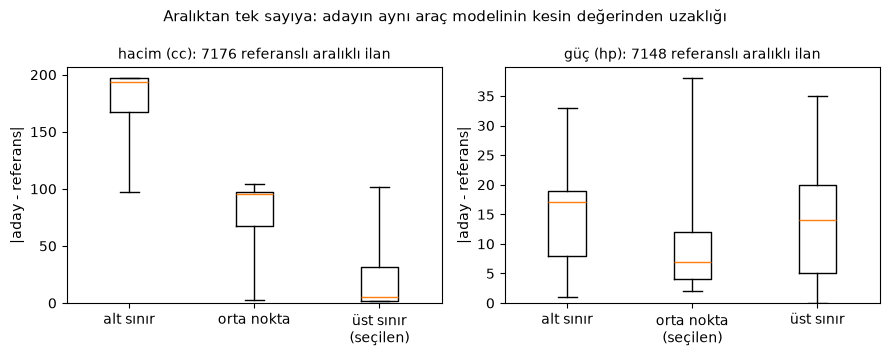

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (measure, label) in zip(axes, MEASURES.items()):
    part = ranged[ranged["measure"] == measure]
    ax.boxplot([part[c] for c in CANDIDATES], whis=(5, 95), showfliers=False)
    ax.set_xticks([1, 2, 3], [name + ("\n(seçilen)" if c == CHOSEN[measure] else "")
                              for c, name in CANDIDATES.items()])
    ax.set_title(f"{label}: {len(part)} referanslı aralıklı ilan", fontsize=10)
    ax.set_ylabel("|aday - referans|")
    ax.set_ylim(bottom=0)
fig.suptitle("Aralıktan tek sayıya: adayın aynı araç modelinin kesin değerinden uzaklığı", fontsize=11)
fig.tight_layout()
plt.show()

### 2.5 Referans aralığın neresinde?

Uzaklığın arkasındaki yapı: referans kendi aralığının neresine düşüyor? **Konum** = (referans - alt sınır) / (üst
sınır - alt sınır); 0 alt sınır, 1 üst sınır demek. Referans aralığın dışındaysa konum 0'ın altında ya da 1'in
üstünde olur. Ayrıca referansın aralığın içinde kaldığı ilanların payını sayıyoruz.

In [31]:
width = ranged["up"] - ranged["low"]
ranged["position"] = (ranged["reference"] - ranged["low"]) / width.where(width > 0)   # genişliği 0 olan yok sayılır
ranged["inside"] = (ranged["reference"] >= ranged["low"]) & (ranged["reference"] <= ranged["up"])

position_table = ranged.groupby("measure")["position"].quantile([0.25, 0.5, 0.75]).unstack().round(3)
position_table["inside_pct"] = (100 * ranged.groupby("measure")["inside"].mean()).round(1)

position_table.rename(index=MEASURES, columns={0.25: "konum: alt çeyrek", 0.5: "konum: medyan",
                                               0.75: "konum: üst çeyrek", "inside_pct": "aralığın içinde (%)"}
                      ).rename_axis("ölçü")

,konum: alt çeyrek,konum: medyan,konum: üst çeyrek,aralığın içinde (%)
ölçü,,,,
hacim (cc),0.839,0.975,0.990,97.9
güç (hp),0.292,0.583,0.792,84.2


**Ne görüyoruz.** Hacimde referans neredeyse hep aralığın üst ucunda: medyan konum 1'e çok yakın, alt çeyrek bile
yüksek; referans ilanların çok büyük kısmında aralığın içinde. Güçte konum dağınık (çeyrekler birbirinden uzak) ve
referans aralığın dışına daha sık düşüyor. Dağınık bir konumda orta nokta en iyi tutan tek sayı.

### 2.6 Aralık aralık en yakın aday

Tek kural bütün aralıklı ilanlara bakıyor. Aralık bazında da aynı mı? En az 100 ilanı olan her aralık için üç
adayın medyan uzaklığını hesaplayıp en yakını seçiyoruz. İki aday berabere kalırsa ikisi de yazılır.

In [32]:
MIN_BUCKET_N = 100

bucket_medians = ranged.groupby(["measure", "low", "up"]).agg(
    n=("lower", "size"), lower=("lower", "median"), mid=("mid", "median"), upper=("upper", "median"))
big_buckets = bucket_medians[bucket_medians["n"] >= MIN_BUCKET_N].copy()

closest = []
for _, row in big_buckets.iterrows():
    best = row[list(CANDIDATES)].min()
    closest.append("+".join(c for c in CANDIDATES if row[c] == best))
big_buckets["closest"] = closest

In [33]:
shown = big_buckets.reset_index()
shown["measure"] = shown["measure"].map(MEASURES)
shown["closest"] = shown["closest"].map(lambda ids: " ile ".join(CANDIDATES[c] for c in ids.split("+")))

shown.rename(columns={"measure": "ölçü", "low": "alt sınır", "up": "üst sınır", "n": "ilan",
                      "lower": "uzaklık: alt", "mid": "uzaklık: orta", "upper": "uzaklık: üst",
                      "closest": "en yakın"})

,ölçü,alt sınır,üst sınır,ilan,uzaklık: alt,uzaklık: orta,uzaklık: üst,en yakın
0,hacim (cc),1201.0,1400.0,123,189.0,89.5,10.0,üst sınır
1,hacim (cc),1401.0,1600.0,4015,196.0,96.5,3.0,üst sınır
2,hacim (cc),1601.0,1800.0,146,197.0,97.5,2.0,üst sınır
3,hacim (cc),1801.0,2000.0,2572,167.0,67.5,32.0,üst sınır
4,hacim (cc),2501.0,3000.0,248,466.0,216.5,33.0,üst sınır
5,güç (hp),101.0,125.0,1266,9.0,3.0,15.0,orta nokta
6,güç (hp),126.0,150.0,1361,24.0,12.0,0.0,üst sınır
7,güç (hp),151.0,175.0,2128,19.0,7.0,5.0,üst sınır
8,güç (hp),176.0,200.0,1695,8.0,11.0,23.0,alt sınır
9,güç (hp),201.0,225.0,256,3.0,9.0,21.0,alt sınır


**Ne görüyoruz.** Hacimde en az 100 ilanlı aralıkların hepsinde en yakın aday üst sınır. Güçte en yakın aday güç
düzeyine göre değişiyor: düşük güçte orta nokta, ardından üst sınır, daha yüksek güçte alt sınır (bir aralıkta alt
sınır ile orta nokta berabere). Hiçbiri her yerde kazanmıyor; tek bir kural olarak orta nokta, bütün aralıklı
ilanlarda medyan uzaklığı en küçük aday.

### 2.7 Bir örnek ve aralığın dışına düşen referans

Somut bir örnek: her ölçüde en sık görülen aralık hangisi ve o aralıktaki araç modellerinin kesin değerli
ilanlarında en sık hangi değer yazıyor?

In [34]:
examples = {}
for measure in MEASURES:
    part = ranged[ranged["measure"] == measure]
    sizes = part.groupby(["low", "up"]).size().sort_values(ascending=False)
    low, up = sizes.index[0]
    models_in_range = part.loc[(part["low"] == low) & (part["up"] == up), "model"].unique()
    measure_exact = exact[exact["measure"] == measure]
    values = measure_exact.loc[measure_exact["model"].isin(models_in_range), "up"].value_counts()
    examples[measure] = {"low": low, "up": up, "n": sizes.iloc[0],
                         "exact_value": values.index[0], "exact_n": values.iloc[0]}
example_table = pd.DataFrame(examples).T.astype(int)

example_table.rename(index=MEASURES, columns={"low": "alt sınır", "up": "üst sınır", "n": "referanslı ilan",
                                              "exact_value": "en sık kesin değer", "exact_n": "o değerde ilan"})

,alt sınır,üst sınır,referanslı ilan,en sık kesin değer,o değerde ilan
hacim (cc),1401,1600,4015,1598,4279
güç (hp),151,175,2128,170,4613


Hacimdeki örnekte üç aday en sık kesin değere ne kadar uzak?

In [35]:
cc_low, cc_up, cc_value = example_table.loc["engine_cc", ["low", "up", "exact_value"]]
for name, value in [("alt sınır", cc_low), ("orta nokta", (cc_low + cc_up) / 2), ("üst sınır", cc_up)]:
    print(f"{name} {value:g} cc: en sık kesin değerden {abs(value - cc_value):g} cc uzak")

alt sınır 1401 cc: en sık kesin değerden 197 cc uzak
orta nokta 1500.5 cc: en sık kesin değerden 97.5 cc uzak
üst sınır 1600 cc: en sık kesin değerden 2 cc uzak


Sebep motorların litre etiketi: "1.6" diye satılan bir motorun gerçek hacmi etiketin birkaç cc altında. Sitenin
aralıkları da bu etiket değerlerinde bitiyor, bu yüzden gerçek hacim neredeyse her zaman üst sınırın dibinde. Güçte
böyle bir etiket yok; gerçek değerler aralığın içine dağılıyor.

Referans aralığın dışına düştüğünde suçlu kim: sitenin aralığı mı, referans mı? Bir araç modeli adı birden çok
motor seçeneğini kapsayabilir; o zaman kesin değerli ilanları birden çok farklı değer taşır ve medyanları kaba bir
referanstır. Aralığın dışına düşen ilanlarda, araç modelinin birden çok kesin değeri olanların payı:

In [36]:
n_exact_values = exact.groupby(["measure", "model"])["up"].nunique().rename("n_exact_values").reset_index()
outside = ranged[~ranged["inside"]].merge(n_exact_values, on=["measure", "model"], how="left")
outside_multi_pct = (100 * (outside["n_exact_values"] > 1).groupby(outside["measure"]).mean()).round(1)

outside_multi_pct.rename(index=MEASURES).rename_axis("ölçü").rename(
    "birden çok kesin değeri olan araç modeli (%)").to_frame()

,birden çok kesin değeri olan araç modeli (%)
ölçü,
hacim (cc),26.4
güç (hp),90.3


**Ne görüyoruz.** Güçte referansın aralık dışında kaldığı ilanların çok büyük kısmında araç modelinin birden çok
kesin güç değeri var: aynı araç modeli adı farklı motor seçenekleri taşıyor. Yani güçteki "dışarıda" payı sitenin
aralığının değil, referansın kabalığını gösteriyor.

### 2.8 Sitenin verdiği değerler

Son olarak sitenin bir ölçü için verdiği bütün (alt sınır, üst sınır) çiftleri ve her çiftin ilan sayısı. Kesin
değer köşegende durur (alt = üst), aralık köşegenin üstünde. Açık uçlu aralıklar ve değeri olmayan ilanlar
çizilmez.

In [37]:
pairs = (bounds.dropna(subset=["low", "up"]).groupby(["measure", "is_range", "low", "up"]).size()
         .rename("n").reset_index())
print("Farklı (alt, üst) çifti:", pairs.groupby("measure").size().rename(MEASURES).to_dict())

Farklı (alt, üst) çifti: {'hacim (cc)': 60, 'güç (hp)': 96}


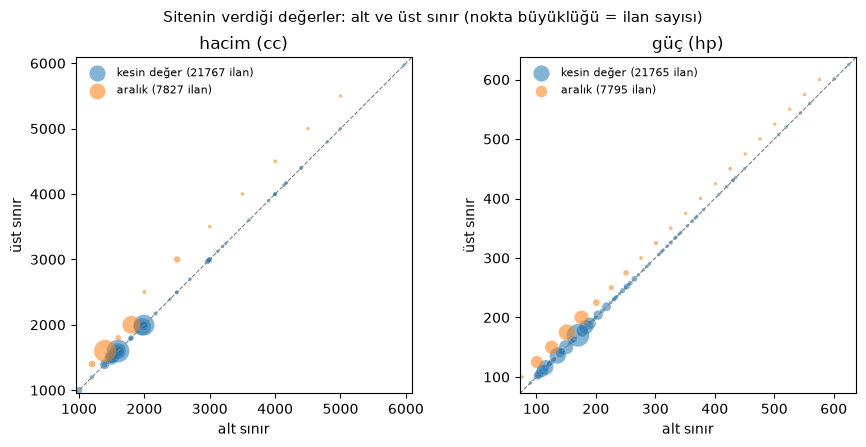

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, (measure, label) in zip(axes, MEASURES.items()):
    part = pairs[pairs["measure"] == measure]
    for is_range, name in [(False, "kesin değer"), (True, "aralık")]:
        p = part[part["is_range"] == is_range]
        ax.scatter(p["low"], p["up"], s=6 + 260 * p["n"] / part["n"].max(), alpha=0.55, lw=0,
                   label=f"{name} ({p['n'].sum()} ilan)")
    lim = [part[["low", "up"]].min().min() * 0.95, part[["low", "up"]].max().max() * 1.02]
    ax.plot(lim, lim, "--", color="grey", lw=0.8)
    ax.set(xlim=lim, ylim=lim, aspect="equal", title=label, xlabel="alt sınır", ylabel="üst sınır")
    ax.legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Sitenin verdiği değerler: alt ve üst sınır (nokta büyüklüğü = ilan sayısı)", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Hacimde aralıklar az sayıda geniş basamak; kesin değerler köşegende bu basamakların üst ucuna
yakın kümeleniyor. Güçte aralıklar dar ve sık; kesin değerler aralıkların içine yayılıyor.

## 3. Belirtilmemiş paneller

**Soru.** Site her ilan için 13 kaporta parçasının her birine beş cevaptan birini veriyor: orijinal,
belirtilmemiş, boyalı, lokal boyalı, değişmiş. Veritabanı her parçayı üç bayrakla tutar (değişen, boyalı, lokal
boyalı); "belirtilmemiş" cevabında üç bayrak da boş kalır. `data.add_features` boş bayrağı 0 sayar, yani
belirtilmemiş parça tahmin modeline orijinal görünür. Bu bilinçli bir karar: satıcı hasarı yazmayı unutmuş
olabilir, ama hasar olmaması daha olası sayıldı. Kararın kapsamı ne: kaç parça ve kaç ilan belirtilmemiş cevap
taşıyor?

Sayım sitenin ham cevaplarından yapılıyor. Önce ham cevapların veritabanının bayraklarıyla bire bir aynı olduğu
gösteriliyor, sonra sayılıyor.

### 3.1 Sitenin cevapları ve veritabanının kodları

Ham cevabı koda çeviren eşleme `db/dblib/damage_mappings.json` dosyasında; veritabanını kuran kod da aynı dosyayı
okuyor. İki sözlük var: parça adı → durum kolonu ve cevap → kod.

In [39]:
damage_maps = json.loads(data.DAMAGE_MAPPINGS.read_text(encoding="utf-8"))
panel_map = damage_maps["panels"]      # sitedeki parça adı -> durum kolonu (ör. "Tavan" -> "roof_status")
status_map = damage_maps["statuses"]   # sitedeki cevap -> kod (ör. "Belirtilmemiş" -> "unspecified")
status_columns = list(panel_map.values())
unspecified = status_map["Belirtilmemiş"]

print(len(panel_map), "parça:", ", ".join(panel_map))
pd.Series(status_map).rename_axis("sitedeki cevap").rename("kod").to_frame()

13 parça: Tavan, Motor Kaputu, Arka Kaput, Ön Tampon, Arka Tampon, Sol Ön Kapı, Sağ Ön Kapı, Sol Arka Kapı, Sağ Arka Kapı, Sol Ön Çamurluk, Sağ Ön Çamurluk, Sol Arka Çamurluk, Sağ Arka Çamurluk


,kod
sitedeki cevap,
Orjinal,original
Belirtilmemiş,unspecified
Boyalı,painted
Lokal boyalı,local_painted
Değişmiş,changed


### 3.2 Ham sayfalardan hasar listeleri

Veri toplama kodunun kaydettiği ham sayfalar `data/raw/<marka>/<tarama>/details.jsonl` dosyalarında: her satır bir
ilan sayfasının bir taramadaki hâli. `cleaning.read_damage_lists` her sayfadan yalnız üç alan okur: ilan numarası,
tarama günü ve hasar listesi ("parça: cevap" biçiminde 13 metin). Parça ve cevabı yukarıdaki eşlemeden geçirir;
eşlemede olmayan bir parça ya da cevap görülürse durur. Hasar listesi olmayan sayfalar atlanır. Öteki alanlara,
satıcı açıklaması dahil, dokunulmaz; dosyalar yalnız okunur. Bütün ham dosyaları okuduğu için bu hücre biraz sürer.

In [40]:
damage = cleaning.read_damage_lists(panel_map, status_map)
print("Hasar listesi olan sayfa:", len(damage))

Hasar listesi olan sayfa: 45315


Aynı ilan aynı taramada iki kez görüldüyse hangisinin doğru olduğu bilinemez; ikisi de atılır. Ardından tablonun
ilk üç satırı, ilan numarası olmadan; tablo yan çevrildi (`.T`), yani her kolon bir sayfa.

In [41]:
duplicated_pages = damage.duplicated(["ad_id", "snap"], keep=False)
damage_unique = damage[~duplicated_pages]
print("Aynı taramada iki kez görülen sayfa:", duplicated_pages.sum())

damage_unique.drop(columns="ad_id").head(3).T

Aynı taramada iki kez görülen sayfa: 0


,0,1,2
snap,2026-01-18,2026-01-18,2026-01-18
fender_rr_status,original,unspecified,original
trunk_lid_status,original,unspecified,original
fender_rl_status,original,unspecified,original
door_rr_status,original,unspecified,original
door_fr_status,original,unspecified,changed
roof_status,original,unspecified,original
door_rl_status,original,unspecified,original
door_fl_status,original,unspecified,original
fender_fl_status,original,unspecified,painted


### 3.3 İlanlarla eşleştirme

Ham cevaplar ilanlara ilan numarası ve tarama günüyle bağlanıyor: her ilan, son görüldüğü taramadaki hasar
listesiyle. `validate="one_to_one"` iki tarafta da tekrar varsa hata verir.

In [42]:
matched = listings.merge(damage_unique, on=["ad_id", "snap"], how="inner", validate="one_to_one")
print("Eşleşen ilan:", len(matched), "/", len(listings))

Eşleşen ilan: 29988 / 29988


Ham cevaplar veritabanıyla aynı mı? `cleaning.flags_from_statuses` her parçanın üç bayrağını ham cevaptan yeniden
kurar ("değişmiş" cevabı değişen bayrağını, "boyalı" boyalı bayrağını, "lokal boyalı" lokal bayrağını 1 yapar).
Bunlar veritabanının bayraklarıyla, boş bayrak 0 sayılarak karşılaştırılıyor. Ayrıca veritabanında bir parçanın üç
bayrağı birden boşsa ham cevabın "belirtilmemiş" olup olmadığına bakılıyor.

In [43]:
rebuilt = cleaning.flags_from_statuses(matched[status_columns], status_map)
db_flags = matched[rebuilt.columns].fillna(0).astype(int)
flag_differences = (rebuilt != db_flags).sum().sum()
print(rebuilt.shape[1], "bayrak, bütün eşleşen ilanlarda; ham cevaptan farklı değer:", flag_differences)

empty_vs_unspecified = 0
for column in status_columns:
    flags = [f"{cleaning.flag_prefix(column)}_{suffix}" for suffix in cleaning.FLAG_OF_ANSWER.values()]
    all_empty = matched[flags].isna().all(axis=1)
    empty_vs_unspecified += (all_empty != (matched[column] == unspecified)).sum()
print("Üç bayrağı birden boş olma ile 'belirtilmemiş' cevabın ayrıştığı parça:", empty_vs_unspecified)

39 bayrak, bütün eşleşen ilanlarda; ham cevaptan farklı değer: 0
Üç bayrağı birden boş olma ile 'belirtilmemiş' cevabın ayrıştığı parça: 0


**Ne görüyoruz.** Ham cevaptan kurulan bayraklar veritabanıyla birebir aynı, ve veritabanında üç bayrağı birden
boş olan parça tam olarak "belirtilmemiş" cevabı. Yani ayrım veritabanında duruyor; belirtilmemiş parçanın 0
sayılması `data.add_features`'ta oluyor.

### 3.4 Sayım

Önce bütün parça cevaplarının dağılımı, sonra ilan başına kaç parçanın belirtilmemiş olduğu.

In [44]:
answers = matched[status_columns]
n_panel_answers = answers.notna().sum().sum()
n_unspecified = (answers == unspecified).sum().sum()
print(f"Parça cevabı: {n_panel_answers}, belirtilmemiş: {n_unspecified} (%{100 * n_unspecified / n_panel_answers:.1f})")

site_label = {code: label for label, code in status_map.items()}   # kod -> sitedeki cevap, yalnız gösterim için
answers.stack().value_counts().rename(index=site_label).rename_axis("cevap").rename("parça").to_frame()

Parça cevabı: 389844, belirtilmemiş: 59651 (%15.3)


,parça
cevap,
Orjinal,256281
Belirtilmemiş,59651
Boyalı,42719
Lokal boyalı,17806
Değişmiş,13387


In [45]:
unspecified_per_listing = (answers == unspecified).sum(axis=1)
print("En az bir parçası belirtilmemiş ilan:", (unspecified_per_listing > 0).sum())
print("13 parçasının hepsi belirtilmemiş ilan:", (unspecified_per_listing == len(status_columns)).sum())

per_listing_counts = unspecified_per_listing.value_counts().sort_index()
per_listing_counts.rename_axis("belirtilmemiş parça sayısı").rename("ilan").to_frame().T

En az bir parçası belirtilmemiş ilan: 6236
13 parçasının hepsi belirtilmemiş ilan: 1235


belirtilmemiş parça sayısı,0,1,2,3,4,5,6,7,8,9,10,11,12,13
ilan,23752,131,352,107,107,146,167,269,443,659,787,944,889,1235


**Ne görüyoruz.** Belirtilmemiş, orijinalden sonra en sık cevap. İlanlara göre dağılım iki uçlu: ilanların
çoğunda hiç belirtilmemiş parça yok; bir grup ilanda 13 parçanın hepsi belirtilmemiş (satıcı hasar şemasını hiç
doldurmamış). Arada kalanların çoğunda parçaların çoğu belirtilmemiş: satıcı yalnız birkaç parçayı işaretlemiş.
Tahmin modeli bu ilanların belirtilmemiş parçalarını orijinal görüyor; hasarlı olup bunu yazmamış bir satıcının
aracı tahmin modeline hasarsız görünür.

## 4. Eksiklik

**Soru.** Hangi ham kolonlar boş, hangileri birlikte boş, kb/gb ikizlerinden hangisi tutuldu ve her ham kolon
tahmin modeline neden girdi ya da neden atıldı? Bu bölüm türetme yapılmamış ilan tablosuna (`raw_listings`) bakar:
`"missing"` ile doldurulmuş hâl boşlukları gizlerdi.

### 4.1 Boşluk ile "belirtilmemiş" ayrı şeyler

Bazı kolonlarda boş değer eksik veri değil, sayfanın "belirtilmemiş" cevabı: ağır hasar kaydı (iki sekmede), ilk
sahip bilgisi, 39 parça bayrağı ve hasar sayaçları. Tahmin modeli bu bilinmeyeni bilinçli bir kararla "yok" okur:
hayır ya da 0. Bu kolonların listesi veritabanı kolunun doldurma kurallarından okunuyor (`data.FILL_RULES`).
Bu kolonlar eksik listesine ve bloklara girmez; boş payları burada ayrıca gösteriliyor.

In [46]:
fill_rules = json.loads(data.FILL_RULES.read_text(encoding="utf-8"))
coded = [column for rule in fill_rules["fill"] for column in rule["columns"]]
coded_pct = (100 * raw_listings[coded].isna().mean()).round(1)
panel_flags = [column for column in coded if column.endswith(("_degisen", "_boyali", "_lokal"))]
counters = [column for column in coded if column.startswith("count_")]
print(len(coded), "kolon;", len(panel_flags), "tanesi parça bayrağı")

pd.Series({"heavy_damage": coded_pct["is_heavy_damaged"], "kb_heavy_damage": coded_pct["kb_is_heavy_damaged"],
           "first_owner": coded_pct["gb_is_first_owner"], "panel_min": coded_pct[panel_flags].min(),
           "panel_max": coded_pct[panel_flags].max(), "counter_max": coded_pct[counters].max()}).rename({
    "heavy_damage": "ağır hasar kaydı", "kb_heavy_damage": "ağır hasar kaydı (kısa bilgi)",
    "first_owner": "ilk sahip", "panel_min": "parça bayrağı: en az", "panel_max": "parça bayrağı: en çok",
    "counter_max": "hasar sayacı: en çok"}).to_frame("belirtilmemiş (%)")

45 kolon; 39 tanesi parça bayrağı


,belirtilmemiş (%)
ağır hasar kaydı,68.2
ağır hasar kaydı (kısa bilgi),68.2
ilk sahip,0.0
parça bayrağı: en az,12.2
parça bayrağı: en çok,19.1
hasar sayacı: en çok,0.0


**Ne görüyoruz.** Ağır hasar kaydı ilanların çoğunda belirtilmemiş; parça bayrakları her parçada ilanların küçük
bir kısmında. İlk sahip bilgisi ve hasar sayaçları neredeyse hiç boş değil.

### 4.2 Boş kolonlar

Geri kalan kolonlarda boş payı. %2'den fazla boş olan kolonlar, en boştan aza:

In [47]:
missing_pct = 100 * raw_listings.drop(columns=coded).isna().mean()
missing_list = missing_pct[missing_pct > 2].round(1).sort_values(ascending=False, kind="stable")
print(len(missing_list), "kolon %2'den fazla boş")

missing_list.rename_axis("kolon").rename("boş (%)").to_frame()

32 kolon %2'den fazla boş


,boş (%)
kolon,
tramer_fee,84.4
transmission_brand,74.1
gb_drivetrain,74.0
gb_traffic_insurance_avg,54.3
gb_kasko_avg,51.1
gb_mtv_yearly,40.6
city_fuel_cons,31.4
highway_fuel_cons,31.4
production_year_start,29.9


### 4.3 Birlikte boş kalan bloklar

Listede aynı boş payını taşıyan çok sayıda kolon var. Bunlar aynı ilanlarda mı boş? `missing.comissing_blocks`
%20'den fazla boş kolonları bloklara ayırır. İki kolonun uzaklığı 1 eksi **birlikte eksik payı**: ikisinin birden
boş olduğu ilanların, en az birinin boş olduğu ilanlara oranı. Ortalama bağlantılı hiyerarşik kümeleme 0.02
uzaklıkta kesilir, yani bir bloktaki kolonlar ortalamada en az %98 birlikte boş. Aşağıdaki tablo her bloğun kolon
sayısını, kolonlarının ortalama boş payını ve bloğun bütün kolonları için birlikte eksik payını
(`missing.co_missing_share`) gösteriyor.

In [48]:
BLOCK_RATE, BLOCK_DIST = 20, 0.02
block_candidates = list(missing_list[missing_list > BLOCK_RATE].index)
blocks = missing.comissing_blocks(raw_listings, block_candidates, BLOCK_DIST)

block_table = pd.DataFrame({
    "n_columns": [len(block) for block in blocks],
    "mean_missing_pct": [round(missing_list[block].mean(), 1) for block in blocks],
    "co_missing_pct": [round(100 * missing.co_missing_share(raw_listings, block), 1) for block in blocks],
    "columns": [", ".join(block) for block in blocks]}, index=range(1, len(blocks) + 1))

block_table.rename_axis("blok").rename(columns={"n_columns": "kolon", "mean_missing_pct": "ortalama boş (%)",
                                                "co_missing_pct": "birlikte boş (%)", "columns": "kolonlar"})

,kolon,ortalama boş (%),birlikte boş (%),kolonlar
blok,,,,
1,16,27.6,98.8,"weight_kg, kb_fuel_cons_avg, kb_fuel_tank, gb_segment, torque_nm, cylinder_count, max_speed_kmh, accel_0_100, length_mm, width_mm, height_mm, curb_weight_kg, trunk_capacity_lt, wheelbase_mm, front_tire_spec, seat_count"
2,2,31.4,100.0,"city_fuel_cons, highway_fuel_cons"
3,2,29.9,100.0,"production_year_start, production_year_end"
4,2,29.3,100.0,"rpm_max, rpm_min"


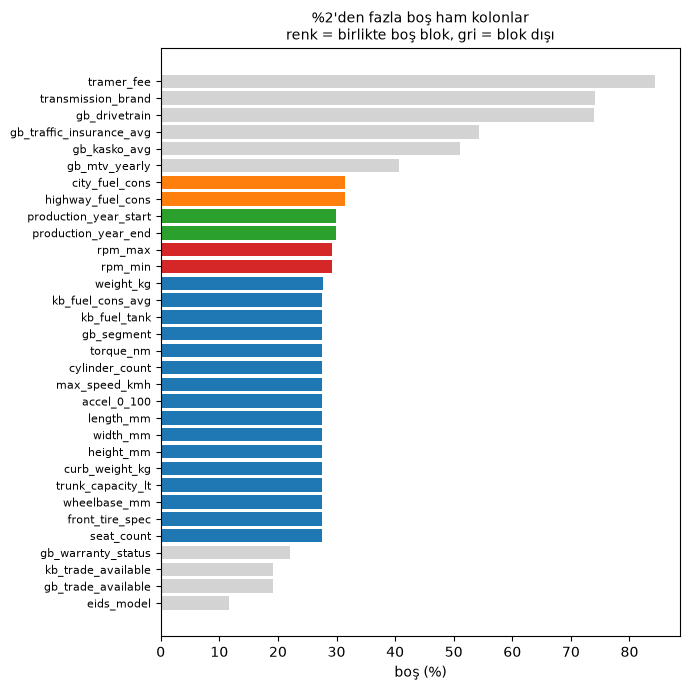

In [49]:
block_of = {column: i for i, block in enumerate(blocks) for column in block}
colors = [f"C{block_of[c]}" if c in block_of else "lightgrey" for c in missing_list.index]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(missing_list.index[::-1], missing_list.values[::-1], color=colors[::-1])
ax.set_xlabel("boş (%)")
ax.set_title("%2'den fazla boş ham kolonlar\nrenk = birlikte boş blok, gri = blok dışı", fontsize=10)
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Boş kolonların çoğu birkaç blokta toplanıyor ve bir bloğun kolonları neredeyse her zaman birlikte
boş. Bunlar rastgele eksik veri değil, katalog eşleşmesinin tutmadığı ilanlar: standart araç modelleri eşleşir, niş
varyantlar eşleşmez ve bütün teknik özellik listesi birden boşalır. Boşluk sistematik olduğu için güvenilir bir
doldurma yok; bu kolonlar atıldı. Blok dışındaki boş kolonlar başka sebeplerle boş; her biri aşağıda kendi sınıfında
atılıyor.

### 4.4 kb/gb ikizleri

İlan sayfasında aynı bilgi iki bölümde yer alabiliyor: `kb_` kısa bilgi, `gb_` genel bakış. Önce tahmin modelinin
öznitelikleri hangi ham kolonlardan geliyor, onu topluyoruz. Çoğu doğrudan bir ham kolon. Türetilenlerin kaynağı:
yaş `gb_year` ve `search_date`, güç iki sınır, hacim üst sınır, segment seri ve araç modeli; hasar öznitelikleri 39
parça bayrağından.

In [50]:
FEATURE_SOURCES = {"vehicle_age": ["gb_year", "search_date"], "power_hp_val": ["power_hp_low", "power_hp_up"],
                   "engine_cc_val": ["engine_cc_up"], "segment": ["series", "model"]}
DAMAGE_FEATURES = ("roof_state", "hood_state", "trunk_state", "door_", "fender_", "bumper_")
flag_columns = [column for column in raw_listings.columns if column.endswith(("_degisen", "_boyali", "_lokal"))]

used = set()
for feature in data.FEATURES:
    used.update(flag_columns if feature.startswith(DAMAGE_FEATURES) else FEATURE_SOURCES.get(feature, [feature]))
print(len(used), "ham kolon tahmin modeline giriyor; bunların", len(flag_columns), "tanesi parça bayrağı")

53 ham kolon tahmin modeline giriyor; bunların 39 tanesi parça bayrağı


`missing.twin_table` her ikiz çift için iki tarafın boş paylarını, farklı değer sayılarını ve iki tarafın aynı
olduğu ilanların payını (ikisi de boşsa aynı) hesaplar; ağır hasar kaydının da bir ikizi var (`kb_is_heavy_damaged`
ile `is_heavy_damaged`). Tahmin modeli bir tarafı kullanıyorsa öteki atılır. Hiçbir tarafı kullanmıyorsa `gb_`
tarafı ikiz olarak atılır; `kb_` tarafı aşağıda kendi sınıfına bakılmak üzere kalır. Atılan tarafın gerekçesi: iki
taraf birebir aynı (en az %99.9), atılan taraf %40'tan fazla boş ya da elle verilmiş bir gerekçe. Gerekçesi olmayan
atılmış bir taraf kalırsa fonksiyon durur.

Elle verilen tek gerekçe kasa tipinde: `kb_body_type` daha genel olduğu için seçildi; `gb_body_type` aynı bilgiyi
koltuk sayısıyla birleştiriyor. Kasa tipi iki tarafta da boş olan ilanlarda kasa tipi araç modeli adından
çıkarılmıyor: aynı araç modeli adı farklı kasa tiplerinde satılabiliyor. Bu ilanlar `missing` kategorisinde kalıyor.

In [51]:
TWIN_BY_HAND = {"gb_body_type": "kb daha genel: gb kasa tipini koltuk sayısıyla birleştiriyor"}
twins = missing.twin_table(raw_listings, used, TWIN_BY_HAND)

reasons = []
for _, twin in twins.iterrows():
    if twin["reason"] == "by_hand":
        reasons.append(TWIN_BY_HAND[twin["dropped"]])
    elif twin["reason"] == "identical":
        reasons.append("öteki tarafla birebir aynı")
    else:
        reasons.append(f"%{twin['dropped_missing_pct']:.0f} boş")

In [52]:
twin_view = twins.assign(kept=twins["kept"].fillna("hiçbiri"), reason=reasons).drop(columns="dropped_missing_pct")

twin_view.round(1).rename(columns={
    "kb": "kısa bilgi", "gb": "genel bakış", "kb_missing_pct": "kb boş (%)", "gb_missing_pct": "gb boş (%)",
    "kb_unique": "kb farklı değer", "gb_unique": "gb farklı değer", "same_pct": "aynı (%)",
    "kept": "tutulan", "dropped": "atılan", "reason": "gerekçe"})

,kısa bilgi,genel bakış,kb boş (%),gb boş (%),kb farklı değer,gb farklı değer,aynı (%),tutulan,atılan,gerekçe
0,kb_year,gb_year,0.0,0.0,22,22,100.0,gb_year,kb_year,öteki tarafla birebir aynı
1,kb_mileage,gb_mileage,0.0,0.0,3109,3109,100.0,gb_mileage,kb_mileage,öteki tarafla birebir aynı
2,kb_transmission,gb_transmission,0.0,0.0,3,3,100.0,kb_transmission,gb_transmission,öteki tarafla birebir aynı
3,kb_fuel,gb_fuel,0.0,0.0,4,4,100.0,kb_fuel,gb_fuel,öteki tarafla birebir aynı
4,kb_body_type,gb_body_type,1.0,0.7,9,23,77.5,kb_body_type,gb_body_type,kb daha genel: gb kasa tipini koltuk sayısıyla birleştiriyor
5,kb_color,gb_color,0.0,0.0,24,24,100.0,hiçbiri,gb_color,öteki tarafla birebir aynı
6,kb_drivetrain,gb_drivetrain,1.5,74.0,4,4,27.5,kb_drivetrain,gb_drivetrain,%74 boş
7,kb_condition,gb_condition,0.0,0.0,2,2,100.0,hiçbiri,gb_condition,öteki tarafla birebir aynı
8,kb_trade_available,gb_trade_available,19.1,19.1,2,2,100.0,hiçbiri,gb_trade_available,öteki tarafla birebir aynı
9,kb_seller_type,gb_seller_type,0.0,0.0,3,3,100.0,hiçbiri,gb_seller_type,öteki tarafla birebir aynı


**Ne görüyoruz.** Çiftlerin çoğunda iki sekme birebir aynı. Çekişte genel bakış tarafı çoğunlukla boş, kısa bilgi
tarafı neredeyse dolu. Kasa tipinde iki taraf her ilanda aynı değil: kısa bilgi tarafı az sayıda genel kategori,
genel bakış tarafı koltuk sayısıyla bölünmüş çok daha fazla değer taşıyor. Renk, araç durumu, takas ve satıcı türü
çiftlerinde hiçbir taraf tahmin modelinde değil.

### 4.5 Her ham kolon nereye gitti

Her ham kolon (veritabanının `id` kolonu dışında) aşağıdaki sınıflardan tam birine atanır. Sıra önceliktir: bir kolon
birden çok koşula uyuyorsa ilk uyduğu sınıfa girer.

| sınıf | koşul |
|---|---|
| tahmin modelinde | bir özniteliğin kaynağı (doğrudan ya da türetilerek) |
| hedef | `price` |
| kimlik / metin / zaman | ilan numarası, adres, başlık, konum, açıklama, tarih gibi kolonlar (`IDENTITY`) |
| türetilmiş tekrar | başka kolonlardan türeyen bilgi (`DERIVED`) |
| kb/gb ikizi | ikiz çiftin atılan tarafı |
| yarı sabit | en sık değer ilanların en az %99'unda |
| çoğu boş | %40'tan fazla boş |
| birlikte boş blok | 4.3'teki bloklardan birinde |
| gerekçe kayıtlı değil | hiçbirine uymayan |

`kb_paint_change_summary` sayfanın kendi "Boya-değişen" satırı ("2 değişen, 3 boyalı" gibi): tahmin modelinin zaten
kullandığı parça bayraklarının kaba özeti, bu yüzden hasar sayaçları gibi türetilmiş tekrar sayılıyor.

In [53]:
IDENTITY = ["ad_id", "url", "listing_date", "ad_title", "location", "scraped_at", "description_text", "eids_model"]
DERIVED = ["engine_cc_low", "engine_cc_val", "engine_cc_is_range", "power_hp_val", "power_hp_is_range",
           "count_changed", "count_painted", "count_local_painted", "kb_paint_change_summary"]

raw_columns = [column for column in raw_listings.columns if column != "id"]
props = pd.DataFrame(index=raw_columns)
props["missing_pct"] = 100 * raw_listings[raw_columns].isna().mean()
props["top_value_pct"] = [round(100 * raw_listings[c].value_counts(dropna=False, normalize=True).iloc[0], 1)
                          for c in raw_columns]

In [54]:
CLASSES = {"model": "tahmin modelinde", "target": "hedef", "identity": "kimlik / metin / zaman",
           "derived": "türetilmiş tekrar", "twin": "kb/gb ikizi", "quasi_constant": "yarı sabit",
           "mostly_missing": "çoğu boş", "block": "birlikte boş blok", "no_reason": "gerekçe kayıtlı değil"}

conditions = [props.index.isin(used), props.index == "price", props.index.isin(IDENTITY),
              props.index.isin(DERIVED), props.index.isin(twins["dropped"]), props["top_value_pct"] >= 99.0,
              props["missing_pct"] > 40, props.index.isin(list(block_of))]
props["class"] = np.select(conditions, list(CLASSES)[:-1], default="no_reason")

class_table = pd.DataFrame({"n": [(props["class"] == k).sum() for k in CLASSES],
                            "columns": [", ".join(props.index[props["class"] == k]) for k in CLASSES]},
                           index=list(CLASSES))
class_table.rename(index=CLASSES, columns={"n": "kolon", "columns": "kolonlar"}).rename_axis("sınıf")

,kolon,kolonlar
sınıf,,
tahmin modelinde,53,"brand, series, model, engine_cc_up, power_hp_low, power_hp_up, gb_year, gb_mileage, kb_transmission, kb_fuel, kb_body_type, kb_drivetrain, is_heavy_damaged, tavan_degisen, tavan_boyali, tavan_lokal, kaput_degisen, kaput_boyali, kaput_lokal, bagaj_degisen, bagaj_boyali, bagaj_lokal, door_fl_degisen, door_fl_boyali, door_fl_lokal, door_fr_degisen, door_fr_boyali, door_fr_lokal, door_rl_degisen, door_rl_boyali, door_rl_lokal, door_rr_degisen, door_rr_boyali, door_rr_lokal, fender_fl_degisen, fender_fl_boyali, fender_fl_lokal, fender_fr_degisen, fender_fr_boyali, fender_fr_lokal, fender_rl_degisen, fender_rl_boyali, fender_rl_lokal, fender_rr_degisen, fender_rr_boyali, fender_rr_lokal, bumper_front_degisen, bumper_front_boyali, bumper_front_lokal, bumper_rear_degisen, bumper_rear_boyali, bumper_rear_lokal, search_date"
hedef,1,price
kimlik / metin / zaman,8,"ad_id, listing_date, ad_title, location, eids_model, url, description_text, scraped_at"
türetilmiş tekrar,9,"engine_cc_low, engine_cc_val, engine_cc_is_range, power_hp_val, power_hp_is_range, count_changed, count_painted, count_local_painted, kb_paint_change_summary"
kb/gb ikizi,11,"kb_year, kb_mileage, gb_transmission, gb_fuel, gb_body_type, gb_color, kb_is_heavy_damaged, gb_drivetrain, gb_condition, gb_seller_type, gb_trade_available"
yarı sabit,4,"kb_condition, gb_usage_type, gb_is_first_owner, gb_plate_origin"
çoğu boş,5,"gb_mtv_yearly, tramer_fee, transmission_brand, gb_kasko_avg, gb_traffic_insurance_avg"
birlikte boş blok,22,"kb_fuel_cons_avg, kb_fuel_tank, gb_segment, torque_nm, cylinder_count, max_speed_kmh, accel_0_100, city_fuel_cons, highway_fuel_cons, length_mm, width_mm, height_mm, weight_kg, curb_weight_kg, trunk_capacity_lt, wheelbase_mm, seat_count, front_tire_spec, production_year_start, production_year_end, rpm_max, rpm_min"
gerekçe kayıtlı değil,4,"kb_color, kb_trade_available, kb_seller_type, gb_warranty_status"


In [55]:
n_in_model = class_table.loc["model", "n"]
n_dropped = len(raw_columns) - n_in_model - class_table.loc["target", "n"]
print(f"{len(raw_columns)} ham kolon: {n_in_model} tahmin modelinde ({len(flag_columns)} tanesi parça bayrağı), "
      f"{class_table.loc['target', 'n']} hedef, {n_dropped} atıldı")

117 ham kolon: 53 tahmin modelinde (39 tanesi parça bayrağı), 1 hedef, 63 atıldı


**Ne görüyoruz.** Ham kolonların yaklaşık yarısı tahmin modeline giriyor; bunların çoğu parça bayrağı. Atılanların
en büyük grubu birlikte boş bloklar; onları ikizler, türetilmiş tekrarlar ve kimlik / metin kolonları izliyor.
Gerekçesi kayıtlı olmayan birkaç kolon var: hiçbir kurala uymuyorlar, tahmin modeline de alınmadılar.

### 4.6 Öznitelikler ne kadar boş

Atılan kolonların aksine tahmin modelinin öznitelikleri neredeyse dolu. Türetmeden sonra her özniteliğin boş payı:
sayısal öznitelikte boş değer, metin ve kategorik öznitelikte `"missing"` kategorisi. Sayısal özniteliklerde
doldurma yapılmıyor; boş değer tahmin modeline boş gider.

In [56]:
missing_share = pd.Series({
    column: (listings[column].isna() if column in data.NUM else listings[column] == "missing").mean()
    for column in data.FEATURES})
feature_missing = (100 * missing_share).round(1).sort_values(ascending=False, kind="stable")
print("Hiç boş olmayan öznitelik:", (missing_share == 0).sum(), "/", len(missing_share))

has_missing = missing_share[missing_share > 0].index
feature_missing[feature_missing.index.isin(has_missing)].rename_axis("öznitelik").rename("boş (%)").to_frame()

Hiç boş olmayan öznitelik: 21 / 25


,boş (%)
öznitelik,
kb_drivetrain,1.5
power_hp_val,1.4
engine_cc_val,1.2
kb_body_type,1.0


**Ne görüyoruz.** Boşluk yalnız birkaç öznitelikte var ve hepsinde küçük: çekiş, güç, hacim ve kasa tipi. Geri
kalan özniteliklerde hiç boş değer yok.

## Özet: ön işleme ve filtreler

Toplanan veriye tahmin modelinden önce sırasıyla şunlar uygulandı:

1. **Plaka:** yalnız TR plakalı satırlar alındı. Mavi plakalı ve plaka bilgisi boş ilanlar tümden dışarıda (1.3).
2. **Tekilleştirme:** `ad_id` başına en son tarama satırı (1.1). Fiyat geçmişi tahmin modeline girmiyor (1.2).
   Aynı aracın yeni numarayla yeniden yayımlanması ölçüldü ama ayıklanmadı (1.5).
3. **"Belirtilmemiş" = yok:** belirtilmemiş parça orijinal, belirtilmemiş ağır hasar kaydı ağır hasarsız sayıldı
   (3 ve 4.1).
4. **Motor aralığı → tek sayı:** hacim aralığın üst sınırı, güç alt ve üst sınırın ortalaması (2).
5. **Hasar:** 39 parça bayrağı 3 durum ve 9 sayı özniteliğine indirildi (Kurulum ve veri).
6. **Eksik değer:** sayısal özniteliklerde doldurma yok; kategorik boşluk ayrı bir `missing` kategorisi (4.6).
   Birlikte boş bloklar, çoğu boş kolonlar, ikizler, kimlik ve türetilmiş kolonlar atıldı (4).
7. **Aykırı değer atılmadı:** fiyat, kilometre ve yaş kırpılmadı.

Sonraki defterler `listings` tablosunun bu hâliyle çalışır.

## Başlık sayıları

Defterin ana sonuçları tek tabloda. Anahtarlar kod adı olduğu için İngilizce; yüzdeler yukarıdaki tablolardaki
gibi yuvarlandı.

In [57]:
gaps = median_gaps.round(1)
n_all_unspecified = (unspecified_per_listing == len(status_columns)).sum()
rows = [
    ("snapshot_rows", int(n_snapshot_rows), "TR plakalı tarama satırı"),
    ("listings", int(n_listings), "ilan (ad_id başına en son satır)"),
    ("snapshots", int(listings["snap"].nunique()), "tarama"),
    ("bmw_listings", int((listings["brand"] == "bmw").sum()), "BMW ilanı"),
    ("audi_listings", int((listings["brand"] == "audi").sum()), "Audi ilanı"),
    ("n_features", len(data.FEATURES), "tahmin modelinin özniteliği"),
    ("seen_again_listings", int(seen_again.sum()), "birden çok taramada görülen ilan"),
    ("price_changed_listings", int(price_changed.sum()), "fiyatı değişen ilan"),
    ("plate_dropped_listings", int(dropped.sum()), "plakası yüzünden dışarıda kalan ilan"),
    ("price_at_cap", int(footprint["at_cap"]), "fiyatı tam tavanda olan ilan"),
    ("max_age", int(footprint["max_age"]), "olabilecek en büyük yaş"),
    ("strict_duplicate_pct", float(duplicate_table.loc["strict", "pct"]), "katı tanımla içerik tekrarı (%)"),
    ("no_price_duplicate_pct", float(duplicate_table.loc["no_price", "pct"]), "fiyat hariç içerik tekrarı (%)"),
    ("cc_ranged_listings", int(split_counts.loc["engine_cc", "is_range"]), "hacmi aralıklı ilan"),
    ("hp_ranged_listings", int(split_counts.loc["power_hp", "is_range"]), "gücü aralıklı ilan"),
    ("cc_gap_lower", float(gaps.loc["engine_cc", "lower"]), "hacim: alt sınırın medyan uzaklığı (cc)"),
    ("cc_gap_mid", float(gaps.loc["engine_cc", "mid"]), "hacim: orta noktanın medyan uzaklığı (cc)"),
    ("cc_gap_upper", float(gaps.loc["engine_cc", "upper"]), "hacim: üst sınırın medyan uzaklığı (cc)"),
    ("hp_gap_lower", float(gaps.loc["power_hp", "lower"]), "güç: alt sınırın medyan uzaklığı (hp)"),
    ("hp_gap_mid", float(gaps.loc["power_hp", "mid"]), "güç: orta noktanın medyan uzaklığı (hp)"),
    ("hp_gap_upper", float(gaps.loc["power_hp", "upper"]), "güç: üst sınırın medyan uzaklığı (hp)"),
    ("cc_inside_pct", float(position_table.loc["engine_cc", "inside_pct"]), "hacim: referans aralığın içinde (%)"),
    ("hp_inside_pct", float(position_table.loc["power_hp", "inside_pct"]), "güç: referans aralığın içinde (%)"),
    ("unspecified_panel_pct", float(round(100 * n_unspecified / n_panel_answers, 1)), "belirtilmemiş parça cevabı (%)"),
    ("at_least_one_unspecified", int((unspecified_per_listing > 0).sum()), "en az bir parçası belirtilmemiş ilan"),
    ("all_unspecified", int(n_all_unspecified), "13 parçası da belirtilmemiş ilan"),
    ("heavy_damage_unspecified_pct", float(coded_pct["is_heavy_damaged"]), "ağır hasar kaydı belirtilmemiş (%)"),
    ("missing_columns_over_2pct", len(missing_list), "%2'den fazla boş ham kolon"),
    ("comissing_blocks", len(blocks), "birlikte boş blok"),
    ("min_block_co_missing_pct", float(block_table["co_missing_pct"].min()), "en düşük blok birlikte boş payı (%)"),
    ("raw_columns", len(raw_columns), "ham kolon"),
    ("raw_columns_in_model", int(n_in_model), "tahmin modeline giren ham kolon"),
    ("raw_columns_dropped", int(n_dropped), "atılan ham kolon"),
    ("raw_columns_no_reason", int(class_table.loc["no_reason", "n"]), "gerekçesi kayıtlı olmayan ham kolon"),
]
headline = {key: value for key, value, _ in rows}

headline_table = pd.DataFrame(rows, columns=["key", "value", "description"], dtype=object).set_index("key")
headline_table.rename_axis("anahtar").rename(columns={"value": "değer", "description": "ne"})

,değer,ne
anahtar,,
snapshot_rows,45159,TR plakalı tarama satırı
listings,29988,ilan (ad_id başına en son satır)
snapshots,4,tarama
bmw_listings,17896,BMW ilanı
audi_listings,12092,Audi ilanı
n_features,25,tahmin modelinin özniteliği
seen_again_listings,10831,birden çok taramada görülen ilan
price_changed_listings,4703,fiyatı değişen ilan
plate_dropped_listings,76,plakası yüzünden dışarıda kalan ilan
